## Fusión inicial de datos del RETC para obtener un solo insumo de emisiones geolocalizadas entre 2015 y 2019

Haré el merge de datos y un poquito de exploración superficial

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
current_directory = os.getcwd()
print("Current working directory:", current_directory)

Current working directory: /Users/gabrielevangelista/thesis-cdmx-air/03-analysis/cleaning_retc


Exploracion para ponerlos todos juntos de la manera más eficiente posible

In [2]:
df_15_air= pd.read_csv("../../02-data/raw/retc_2015_air.csv",usecols=['NRA','CAS','AIRE','ESTADO','MUNICIPIO'])
df_16_air= pd.read_csv("../../02-data/raw/retc_2016_air.csv",usecols=['NRA','CAS','AIRE','ESTADO','MUNICIPIO'])
df_17_air= pd.read_csv("../../02-data/raw/retc_2017_air.csv",usecols=['NRA','CAS','AIRE','ESTADO','MUNICIPIO'])
df_18_air= pd.read_csv("../../02-data/raw/retc_2018_air.csv",usecols=['NRA','CAS','AIRE','ESTADO','MUNICIPIO'])
df_19_air= pd.read_csv("../../02-data/raw/retc_2019_air.csv",usecols=['NRA','CAS','AIRE','ESTADO','MUNICIPIO'])


df_15_19 = pd.merge(df_15_air, df_16_air, how='outer', on=['NRA','CAS','ESTADO','MUNICIPIO'], suffixes=('_2015', '_2016')) \
    .merge(df_17_air, how='outer', on=['NRA','CAS','ESTADO','MUNICIPIO']) \
    .merge(df_18_air, how='outer', on=['NRA','CAS','ESTADO','MUNICIPIO']) \
    .merge(df_19_air, how='outer', on=['NRA','CAS','ESTADO','MUNICIPIO'])


df_15_19.columns = ['NRA',  'ESTADO', 'MUNICIPIO', 'CAS', 'AIRE_2015', 'AIRE_2016', 'AIRE_2017', 'AIRE_2018', 'AIRE_2019',]  
df_15_19.replace({np.nan: 0}, inplace=True)  # Reemplaza los valores 0 con NaN
df_15_19






,NRA,ESTADO,MUNICIPIO,CAS,AIRE_2015,AIRE_2016,AIRE_2017,AIRE_2018,AIRE_2019
0,AAL1512102650,MEXICO,Cuautitlan Izcalli,124-38-9,0.0000,0.0000,0.000,0.00,20400610.00
1,AAL1512102650,MEXICO,Cuautitlan Izcalli,7439-92-1,0.0000,0.0000,0.000,0.00,0.00
2,AAL7Q1503321,MEXICO,Ecatepec de Morelos,124-38-9,0.0000,0.0000,1519079.710,1220569.82,309379.32
3,AAL7Q1510911,MEXICO,Tultitlan,124-38-9,473068.5600,0.0000,9839902.889,10504309.32,11756922.40
4,AAM1503900040,MEXICO,Ixtapaluca,124-38-9,108524.0000,111273.0000,119376.000,0.00,0.00
...,...,...,...,...,...,...,...,...,...
462,WSE1509000002,MEXICO,Tenango del Valle,7439-92-1,3.4164,3.4164,0.000,0.00,0.00
463,YAF1503300413,MEXICO,Ecatepec de Morelos,124-38-9,195343.0000,184490.0000,170925.300,138368.10,0.00
464,YIN3K0901711,DISTRITO FEDERAL,Venustiano Carranza,124-38-9,0.0000,222000.0000,0.000,0.00,0.00
465,YOP0901000433,DISTRITO FEDERAL,Alvaro Obregon,124-38-9,0.0000,0.0000,0.000,0.00,6123000.00


In [3]:
# HAcemos filtro geografico con todo el DF y algunas del Estado de Mexico 

FILTRO_SIMAT_MASTER = [
    # 16 Alcaldias CDMX
    'Alvaro Obregon', 'Azcapotzalco', 'Benito Juarez', 'Coyoacan',
    'Cuajimalpa de Morelos', 'Cuauhtemoc', 'Gustavo A. Madero', 'Iztacalco',
    'Iztapalapa', 'Magdalena Contreras', 'Miguel Hidalgo', 'Milpa Alta',
    'Tlahuac', 'Tlalpan', 'Venustiano Carranza', 'Xochimilco',

    # 31 Municipios Edomex (Cuenca SIMAT)
    'Acolman', 'Atenco', 'Atizapan de Zaragoza', 'Chalco', 'Chiautla',
    'Chicoloapan', 'Chiconcuac', 'Chimalhuacan', 'Coacalco de Berriozabal',
    'Coyotepec', 'Cuautitlan', 'Cuautitlan Izcalli', 'Ecatepec de Morelos',
    'Huehuetoca', 'Ixtapaluca', 'Jaltenco', 'La Paz', 'Melchor Ocampo',
    'Naucalpan de Juarez', 'Nezahualcoyotl', 'Nextlalpan', 'Nicolas Romero',
    'Tecamac', 'Teoloyucan', 'Tepetlaoxtoc', 'Tepotzotlan', 'Texcoco',
    'Tlalnepantla de Baz', 'Tultepec', 'Tultitlan', 'Valle de Chalco Solidaridad',
    'Zumpango'
]


df_15_19_f = df_15_19[df_15_19['MUNICIPIO'].isin(FILTRO_SIMAT_MASTER)].copy()


NOS QUEDAMOS CON SOLO LAS FUENTES MODELABLES!

308 fuentes es el número ideal para tu diseño de investigación. Representa el 66.1% del total de las dos entidades; el tercio restante (158 plantas) corresponde con exactitud a lo que se debía depurar: el corredor Toluca-Lerma al otro lado de la sierra y las zonas industriales lejanas del norte (como Apaxco o Jilotepec)

In [4]:
# Filtramos solo el contaminante proxy para PM que es CO2 (CAS 124-38-9)
co2_1519= df_15_19_f[df_15_19_f['CAS'] == '124-38-9'].reset_index(drop=True)

co2_1519

,NRA,ESTADO,MUNICIPIO,CAS,AIRE_2015,AIRE_2016,AIRE_2017,AIRE_2018,AIRE_2019
0,AAL1512102650,MEXICO,Cuautitlan Izcalli,124-38-9,0.00,0.000,0.000000e+00,0.00,20400610.00
1,AAL7Q1503321,MEXICO,Ecatepec de Morelos,124-38-9,0.00,0.000,1.519080e+06,1220569.82,309379.32
2,AAL7Q1510911,MEXICO,Tultitlan,124-38-9,473068.56,0.000,9.839903e+06,10504309.32,11756922.40
3,AAM1503900040,MEXICO,Ixtapaluca,124-38-9,108524.00,111273.000,1.193760e+05,0.00,0.00
4,ACO7F1510411,MEXICO,Tlalnepantla de Baz,124-38-9,8398210.00,7454250.000,7.927679e+06,0.00,10865760.00
...,...,...,...,...,...,...,...,...,...
303,WAY5T0900211,DISTRITO FEDERAL,Azcapotzalco,124-38-9,0.00,5417235.543,1.411204e+07,5221228.50,0.00
304,YAF1503300413,MEXICO,Ecatepec de Morelos,124-38-9,195343.00,184490.000,1.709253e+05,138368.10,0.00
305,YIN3K0901711,DISTRITO FEDERAL,Venustiano Carranza,124-38-9,0.00,222000.000,0.000000e+00,0.00,0.00
306,YOP0901000433,DISTRITO FEDERAL,Alvaro Obregon,124-38-9,0.00,0.000,0.000000e+00,0.00,6123000.00


In [5]:
pb_1519= df_15_19_f[df_15_19_f['CAS'] == '7439-92-1'].reset_index(drop=True)    
pb_1519

,NRA,ESTADO,MUNICIPIO,CAS,AIRE_2015,AIRE_2016,AIRE_2017,AIRE_2018,AIRE_2019
0,AAL1512102650,MEXICO,Cuautitlan Izcalli,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000
1,ABCHM0900411,DISTRITO FEDERAL,Cuajimalpa de Morelos,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000
2,ABCHM0901021,DISTRITO FEDERAL,Alvaro Obregon,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000
3,AEL1501300158,MEXICO,Atizapan de Zaragoza,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000
4,AGU0901700112,DISTRITO FEDERAL,Venustiano Carranza,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000
5,BMEMB1503311,MEXICO,Ecatepec de Morelos,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000
6,BPP1512102394,MEXICO,Cuautitlan Izcalli,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000
7,CAZ7L1510911,MEXICO,Tultitlan,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000
8,CDCEE1512111,MEXICO,Cuautitlan Izcalli,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000
9,CDOTC0900713,DISTRITO FEDERAL,Iztapalapa,7439-92-1,0.000000,0.000000,0.000000,0.000000,0.000000


In [6]:
no2_1519= df_15_19_f[df_15_19_f['CAS'] == '10102-44-0'].reset_index(drop=True)
no2_1519

,NRA,ESTADO,MUNICIPIO,CAS,AIRE_2015,AIRE_2016,AIRE_2017,AIRE_2018,AIRE_2019
0,BOT851503311,MEXICO,Ecatepec de Morelos,10102-44-0,0.0,0.000,0.000,2001450.0,0.00
1,CFEAD1500211,MEXICO,Acolman,10102-44-0,3025835.5,2807026.000,0.000,0.0,0.00
2,CGI1500200092,MEXICO,Acolman,10102-44-0,0.0,0.000,2994531.890,2374511.0,1953527.94
3,EMS561510411,MEXICO,Tlalnepantla de Baz,10102-44-0,0.0,0.000,0.000,0.0,893346.50
4,EVI6Z1509911,MEXICO,Texcoco,10102-44-0,0.0,0.000,153898.855,0.0,0.00
5,FMM9M0900211,DISTRITO FEDERAL,Azcapotzalco,10102-44-0,0.0,0.000,249774.000,0.0,0.00
6,RPM2W1502411,MEXICO,Cuautitlan,10102-44-0,0.0,0.000,0.000,144350.0,146440.00
7,TCOQT1510411,MEXICO,Tlalnepantla de Baz,10102-44-0,0.0,247956.226,0.000,0.0,0.00
8,TPN0901600351,DISTRITO FEDERAL,Miguel Hidalgo,10102-44-0,0.0,4130740.000,0.000,0.0,0.00


Y AQUÍ aplicamos nuestro factor de conversión estimada entre PM y CO2

In [7]:
pm15_19_df = pd.concat(
    [
        co2_1519.iloc[:, 0:4].reset_index(drop=True),
        #(co2_1519.iloc[:, 4:] * 0.0000633).reset_index(drop=True)
        (co2_1519.iloc[:, 4:] *1).reset_index(drop=True)
    ],
    axis=1
)
pm15_19_df.columns = ['NRA', 'ESTADO', 'MUNICIPIO', 'CAS','PM_2015', 'PM_2016', 'PM_2017', 'PM_2018', 'PM_2019']
pm15_19_df

,NRA,ESTADO,MUNICIPIO,CAS,PM_2015,PM_2016,PM_2017,PM_2018,PM_2019
0,AAL1512102650,MEXICO,Cuautitlan Izcalli,124-38-9,0.00,0.000,0.000000e+00,0.00,20400610.00
1,AAL7Q1503321,MEXICO,Ecatepec de Morelos,124-38-9,0.00,0.000,1.519080e+06,1220569.82,309379.32
2,AAL7Q1510911,MEXICO,Tultitlan,124-38-9,473068.56,0.000,9.839903e+06,10504309.32,11756922.40
3,AAM1503900040,MEXICO,Ixtapaluca,124-38-9,108524.00,111273.000,1.193760e+05,0.00,0.00
4,ACO7F1510411,MEXICO,Tlalnepantla de Baz,124-38-9,8398210.00,7454250.000,7.927679e+06,0.00,10865760.00
...,...,...,...,...,...,...,...,...,...
303,WAY5T0900211,DISTRITO FEDERAL,Azcapotzalco,124-38-9,0.00,5417235.543,1.411204e+07,5221228.50,0.00
304,YAF1503300413,MEXICO,Ecatepec de Morelos,124-38-9,195343.00,184490.000,1.709253e+05,138368.10,0.00
305,YIN3K0901711,DISTRITO FEDERAL,Venustiano Carranza,124-38-9,0.00,222000.000,0.000000e+00,0.00,0.00
306,YOP0901000433,DISTRITO FEDERAL,Alvaro Obregon,124-38-9,0.00,0.000,0.000000e+00,0.00,6123000.00


In [8]:
#pm15_19_df.to_csv("../../02-data/processed/retc_15_19_pm.csv", index=False)

Bien, ahora haremos un solo archivo con todos los establecimientos de estos años — sin duplicados

In [9]:
c2keep = ['NRA', 'NOMBRE', 'SCIAN', 'SECTOR', 'DESCRIPCIÓN SCIAN', 'CLAVE\nAMBIENTAL', 'PRINCIPAL ACTIVIDAD PRODUCTIVA','PARQUE INDUSTRIAL', 'COORDENADA \nUTM X', 'COORDENADA \nUTM Y','LATITUD \nNORTE', 'LONGITUD \nOESTE']

In [10]:
def normalize_col(name):
    return " ".join(name.split())

wanted = {normalize_col(col) for col in c2keep}

# Both COORDENADA \nUTM X and COORDENADA\nUTM X normalize to COORDENADA UTM X. The same handles tabs and other repeated whitespace in your column names.

def read_est(year):
    path = f"../../02-data/raw/retc_{year}_est.csv"
    df = pd.read_csv(path, usecols=lambda col: normalize_col(col) in wanted)
    df.columns = [normalize_col(col) for col in df.columns]
    return df

dfs = [read_est(year) for year in range(2015, 2020)]
est_15_19 = pd.concat(dfs, ignore_index=True)
est_15_19.drop_duplicates(subset=["NRA"], keep="first", inplace=True)
est_15_19.reset_index(drop=True, inplace=True)

In [11]:
#est_15_19.to_csv("../../02-data/processed/retc_15_19_est_complete.csv", index=False)

In [12]:
c2keep_est = ['NRA', 'NOMBRE', 'SCIAN', 'SECTOR', 'PARQUE INDUSTRIAL', 'COORDENADA UTM X', 'COORDENADA UTM Y']

est_15_19 = est_15_19[c2keep_est]
est_15_19.rename(columns={'COORDENADA UTM X': 'COORDENADA_UTM_X', 'COORDENADA UTM Y': 'COORDENADA_UTM_Y'}, inplace=True)
est_15_19



,NRA,NOMBRE,SCIAN,SECTOR,PARQUE INDUSTRIAL,COORDENADA_UTM_X,COORDENADA_UTM_Y
0,AAL7Q1503321,"ALMEXA ALUMINIO SA DE CV,",331310,Metalurgica (incluye la siderurgica),NaN,494987.9919,2.162796e+06
1,AAL7Q1510911,"AZINSA ALUMINIO, S.A DE C.V,AZINSA ALUMINIO, S...",331310,Metalurgica (incluye la siderurgica),NaN,483998.7598,2.171968e+06
2,AAM1503900040,"ACEROS AMERICA S.A. DE C.V.,",331111,Metalurgica (incluye la siderurgica),NaN,505305.7470,2.137438e+06
3,ABCHM0900411,THE AMERICAN BRITISH COWDRAY MEDICAL CENTER I....,622311,Servicios de salud y de asistencia,NaN,470268.7949,2.140333e+06
4,ABCHM0901021,THE AMERICAN BRITISH COWDRAY MEDICAL CENTER I....,622311,Servicios de salud y de asistencia,NaN,478549.0421,2.145131e+06
...,...,...,...,...,...,...,...
766,SUN5Y1505711,"SUN CHEMICAL S.A DE C.V,",325910,Pinturas y tintas,NaN,475889.7293,2.154139e+06
767,TME4T0900211,"TAMMEX S.A. DE C.V.,",339999,Articulos y productos metalicos,NaN,483500.5608,2.155374e+06
768,VME9M1505111,"VIBRACOUSTIC DE MÉXICO S.A. DE C.V.,VIBRACOUSTIC",339999,Pinturas y tintas,ZONA INDUSTRIAL,441180.1269,2.134718e+06
769,YOP0901000433,"OPERADORA TECNOAMBIENTAL SEA, S.A. DE C.V.,OPE...",221110,Generación de energia electrica,NaN,478702.1226,2.138869e+06


In [13]:
#est_15_19.to_csv("../../02-data/processed/retc_15_19_est.csv", index=False)


In [14]:
c2keep_est_min = ['NRA', 'COORDENADA_UTM_X', 'COORDENADA_UTM_Y']
est_15_19_min = est_15_19[c2keep_est_min]
#est_15_19_min.to_csv("../../02-data/processed/retc_15_19_est_min.csv", index=False)


Hacemos un left merge completo de emisores de pm con sus coordenadas y nombres mediante NRA

In [15]:
pmest15_19_complete = pd.merge(pm15_19_df, est_15_19, how='left', on='NRA')
#pmest15_19_complete.to_csv("../../02-data/processed/retc_15_19_pm_est_complete.csv", index=False)
pmest15_19_complete

,NRA,ESTADO,MUNICIPIO,CAS,PM_2015,PM_2016,PM_2017,PM_2018,PM_2019,NOMBRE,SCIAN,SECTOR,PARQUE INDUSTRIAL,COORDENADA_UTM_X,COORDENADA_UTM_Y
0,AAL1512102650,MEXICO,Cuautitlan Izcalli,124-38-9,0.00,0.000,0.000000e+00,0.00,20400610.00,"ALMEXA ALUMINIO SA DE CV,",331310,Cemento y Cal,NaN,478326.4580,2.171540e+06
1,AAL7Q1503321,MEXICO,Ecatepec de Morelos,124-38-9,0.00,0.000,1.519080e+06,1220569.82,309379.32,"ALMEXA ALUMINIO SA DE CV,",331310,Metalurgica (incluye la siderurgica),NaN,494987.9919,2.162796e+06
2,AAL7Q1510911,MEXICO,Tultitlan,124-38-9,473068.56,0.000,9.839903e+06,10504309.32,11756922.40,"AZINSA ALUMINIO, S.A DE C.V,AZINSA ALUMINIO, S...",331310,Metalurgica (incluye la siderurgica),NaN,483998.7598,2.171968e+06
3,AAM1503900040,MEXICO,Ixtapaluca,124-38-9,108524.00,111273.000,1.193760e+05,0.00,0.00,"ACEROS AMERICA S.A. DE C.V.,",331111,Metalurgica (incluye la siderurgica),NaN,505305.7470,2.137438e+06
4,ACO7F1510411,MEXICO,Tlalnepantla de Baz,124-38-9,8398210.00,7454250.000,7.927679e+06,0.00,10865760.00,"ACEROS CORSA S.A. DE C.V.,GERDAU CORSA",331111,Metalurgica (incluye la siderurgica),NaN,486974.9934,2.158333e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
303,WAY5T0900211,DISTRITO FEDERAL,Azcapotzalco,124-38-9,0.00,5417235.543,1.411204e+07,5221228.50,0.00,"WYETH S. DE R.L. DE C.V.,ASPEN",325412,Quimica,INDUSTRIAL VALLEJO,482699.4012,2.155616e+06
304,YAF1503300413,MEXICO,Ecatepec de Morelos,124-38-9,195343.00,184490.000,1.709253e+05,138368.10,0.00,"CARLOS ALBERTO YAÑEZ FERNANDEZ,CARLOS ALBERTO ...",331510,Metalurgica (incluye la siderurgica),NaN,492160.2718,2.158971e+06
305,YIN3K0901711,DISTRITO FEDERAL,Venustiano Carranza,124-38-9,0.00,222000.000,0.000000e+00,0.00,0.00,"YACATEX INTERNACIONAL SA DE CV,YACATEX INTERNA...",313310,"Textiles, fibras e hilos",NaN,490505.4254,2.148596e+06
306,YOP0901000433,DISTRITO FEDERAL,Alvaro Obregon,124-38-9,0.00,0.000,0.000000e+00,0.00,6123000.00,"OPERADORA TECNOAMBIENTAL SEA, S.A. DE C.V.,OPE...",221110,Generación de energia electrica,NaN,478702.1226,2.138869e+06


In [16]:
pmest15_19_complete.replace({0: np.nan}, inplace=True)  # Reemplaza los valores 0 con NaN
pmest15_19_complete.describe()

,PM_2015,PM_2016,PM_2017,PM_2018,PM_2019,SCIAN,COORDENADA_UTM_X,COORDENADA_UTM_Y
count,1.560000e+02,1.640000e+02,1.830000e+02,1.750000e+02,1.850000e+02,308.000000,308.000000,3.080000e+02
mean,2.832663e+07,3.907743e+07,2.539181e+07,6.758897e+06,2.563674e+07,323478.103896,485650.409136,2.157284e+06
std,2.082570e+08,2.251964e+08,1.967046e+08,1.789216e+07,1.285944e+08,55422.716621,8750.475956,1.360862e+04
min,1.042200e+05,1.011013e+05,1.013298e+05,1.000734e+05,1.022400e+05,211110.000000,466757.352500,2.128695e+06
25%,3.162125e+05,2.943066e+05,3.077000e+05,3.262615e+05,3.716400e+05,324191.000000,479179.648950,2.149486e+06
50%,1.632062e+06,1.420364e+06,1.176723e+06,1.260000e+06,1.709479e+06,325610.000000,483060.523750,2.157767e+06
75%,7.437534e+06,7.849193e+06,6.866744e+06,5.657607e+06,8.903543e+06,331512.500000,491367.583225,2.164503e+06
max,2.593573e+09,2.406022e+09,2.566742e+09,1.868948e+08,1.674453e+09,811199.000000,518163.359900,2.195802e+06


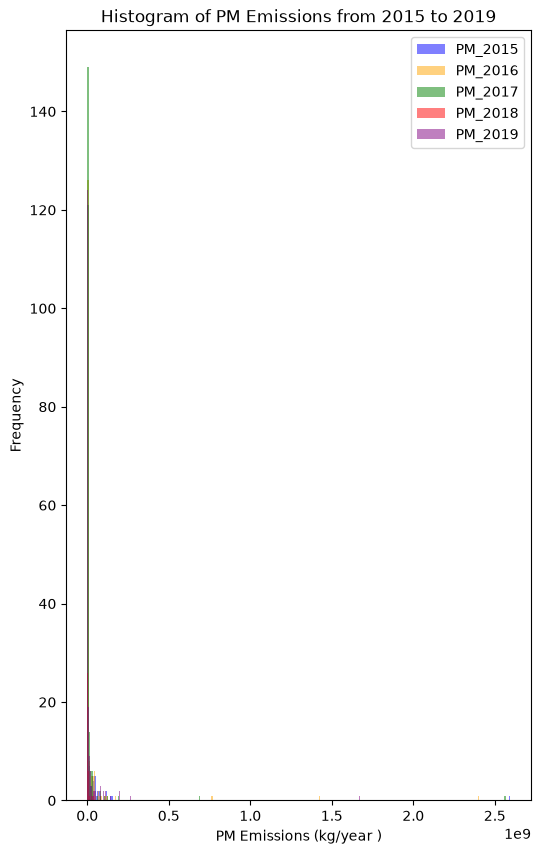

In [17]:
plt.figure(figsize=( 6,10))

# plot histogram of PM_2015
plt.hist(pmest15_19_complete['PM_2015'], bins=300, alpha=0.5, label='PM_2015', color='blue')
plt.hist(pmest15_19_complete['PM_2016'], bins=300, alpha=0.5, label='PM_2016', color='orange')
plt.hist(pmest15_19_complete['PM_2017'], bins=300, alpha=0.5, label='PM_2017', color='green')
plt.hist(pmest15_19_complete['PM_2018'], bins=300, alpha=0.5, label='PM_2018', color='red')
plt.hist(pmest15_19_complete['PM_2019'], bins=300, alpha=0.5, label='PM_2019', color='purple')
plt.xlabel('PM Emissions (kg/year )')
plt.ylabel('Frequency')
plt.title('Histogram of PM Emissions from 2015 to 2019')
plt.legend()



In [18]:
max15= pmest15_19_complete[pmest15_19_complete['PM_2015'] == pmest15_19_complete['PM_2015'].max()][['NOMBRE', 'MUNICIPIO', 'SCIAN', 'COORDENADA_UTM_X', 'COORDENADA_UTM_Y', 'PM_2015','PM_2016', 'PM_2017',  'PM_2018', 'PM_2019']]
max16= pmest15_19_complete[pmest15_19_complete['PM_2016'] == pmest15_19_complete['PM_2016'].max()][['NOMBRE', 'MUNICIPIO', 'SCIAN', 'COORDENADA_UTM_X', 'COORDENADA_UTM_Y', 'PM_2015','PM_2016', 'PM_2017',  'PM_2018', 'PM_2019']]
max17= pmest15_19_complete[pmest15_19_complete['PM_2017'] == pmest15_19_complete['PM_2017'].max()][['NOMBRE', 'MUNICIPIO', 'SCIAN', 'COORDENADA_UTM_X', 'COORDENADA_UTM_Y', 'PM_2015','PM_2016', 'PM_2017',  'PM_2018', 'PM_2019']]
max18= pmest15_19_complete[pmest15_19_complete['PM_2018'] == pmest15_19_complete['PM_2018'].max()][['NOMBRE', 'MUNICIPIO', 'SCIAN', 'COORDENADA_UTM_X', 'COORDENADA_UTM_Y', 'PM_2015','PM_2016', 'PM_2017',  'PM_2018', 'PM_2019']]
max19= pmest15_19_complete[pmest15_19_complete['PM_2019'] == pmest15_19_complete['PM_2019'].max()][['NOMBRE', 'MUNICIPIO', 'SCIAN', 'COORDENADA_UTM_X', 'COORDENADA_UTM_Y', 'PM_2015','PM_2016', 'PM_2017',  'PM_2018', 'PM_2019']]


print("Max PM Emissions for each year:" )


pd.concat([max15, max16, max17, max18, max19], keys=['2015', '2016', '2017', '2018', '2019'])


Max PM Emissions for each year:


,,NOMBRE,MUNICIPIO,SCIAN,COORDENADA_UTM_X,COORDENADA_UTM_Y,PM_2015,PM_2016,PM_2017,PM_2018,PM_2019
2015,63,"COMISIÓN FEDERAL DE ELECTRICIDAD,CENTRAL TERMO...",Acolman,221110,502075.2531,2.169221e+06,2.593573e+09,2.406022e+09,NaN,NaN,NaN
2016,63,"COMISIÓN FEDERAL DE ELECTRICIDAD,CENTRAL TERMO...",Acolman,221110,502075.2531,2.169221e+06,2.593573e+09,2.406022e+09,NaN,NaN,NaN
2017,69,"CFE GENERACION II EPS,CFE GENERACION II",Acolman,221110,503469.0336,2.168840e+06,NaN,NaN,2.566742e+09,NaN,1.674453e+09
2018,106,"EMPAQUES MODERNOS SAN PABLO S.A. DE C.V.,EMPAQ...",Tlalnepantla de Baz,322299,481154.4988,2.157083e+06,6.095586e+07,NaN,NaN,186894837.6,1.978165e+08
2019,69,"CFE GENERACION II EPS,CFE GENERACION II",Acolman,221110,503469.0336,2.168840e+06,NaN,NaN,2.566742e+09,NaN,1.674453e+09


In [19]:
# Filter rows where SCIAN == 221110
pmest15_19_complete[pmest15_19_complete["SCIAN"] == 221110]

,NRA,ESTADO,MUNICIPIO,CAS,PM_2015,PM_2016,PM_2017,PM_2018,PM_2019,NOMBRE,SCIAN,SECTOR,PARQUE INDUSTRIAL,COORDENADA_UTM_X,COORDENADA_UTM_Y
51,CFE0900500336,DISTRITO FEDERAL,Gustavo A. Madero,124-38-9,3.695168e+07,3.695168e+07,NaN,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD, CENTRAL TURB...",221110,Generación de energia electrica,NaN,489345.9221,2.150919e+06
52,CFE0900702250,DISTRITO FEDERAL,Iztapalapa,124-38-9,4.705100e+07,4.705100e+07,NaN,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD,COMISIÓN GENE...",221110,Generación de energia electrica,NaN,492208.5680,2.137795e+06
53,CFE0900702251,DISTRITO FEDERAL,Iztapalapa,124-38-9,4.487134e+07,4.487134e+07,NaN,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD, CENTRAL TURB...",221110,Generación de energia electrica,NaN,493762.8437,2.141301e+06
54,CFE0900702252,DISTRITO FEDERAL,Iztapalapa,124-38-9,3.127900e+07,5.007300e+07,NaN,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD, CENTRAL TURB...",221110,Generación de energia electrica,NaN,490015.5483,2.142851e+06
55,CFE0901300122,DISTRITO FEDERAL,Xochimilco,124-38-9,4.225012e+07,4.225012e+07,NaN,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD, CETRAL TURBO...",221110,Generación de energia electrica,NaN,486615.4391,2.130824e+06
56,CFE0901500457,DISTRITO FEDERAL,Cuauhtemoc,124-38-9,1.743000e+06,1.743000e+06,NaN,NaN,5.492685e+07,"COMISIÓN FEDERAL DE ELECTRICIDAD,CTG NONOALCO",221110,Generación de energia electrica,NaN,484446.4542,2.150572e+06
57,CFE1503300334,MEXICO,Ecatepec de Morelos,124-38-9,4.817800e+07,1.063930e+08,NaN,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD, CENTRAL TURB...",221110,Generación de energia electrica,NaN,494451.9593,2.168278e+06
58,CFE1505700320,MEXICO,Naucalpan de Juarez,124-38-9,4.348400e+07,4.348400e+07,NaN,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD, CENTRL TURBO...",221110,Generación de energia electrica,NaN,472047.5359,2.154868e+06
59,CFE1509500028,MEXICO,Tepotzotlan,124-38-9,1.147240e+08,1.250480e+08,1.250480e+08,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD,COMISION FEDE...",221110,Generación de energia electrica,NaN,477129.3033,2.183689e+06
60,CFE1510400311,MEXICO,Tlalnepantla de Baz,124-38-9,4.633900e+07,4.633900e+07,NaN,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD, CENTRAL TURB...",221110,Generación de energia electrica,NaN,481600.2716,2.157999e+06


In [20]:
pmest15_19_complete[pmest15_19_complete["MUNICIPIO"] == 'Acolman']

,NRA,ESTADO,MUNICIPIO,CAS,PM_2015,PM_2016,PM_2017,PM_2018,PM_2019,NOMBRE,SCIAN,SECTOR,PARQUE INDUSTRIAL,COORDENADA_UTM_X,COORDENADA_UTM_Y
63,CFEAD1500211,MEXICO,Acolman,124-38-9,2.593573e+09,2.406022e+09,NaN,NaN,NaN,"COMISIÓN FEDERAL DE ELECTRICIDAD,CENTRAL TERMO...",221110,Generación de energia electrica,NaN,502075.2531,2.169221e+06
69,CGI1500200092,MEXICO,Acolman,124-38-9,NaN,NaN,2.566742e+09,NaN,1.674453e+09,"CFE GENERACION II EPS,CFE GENERACION II",221110,Generación de energia electrica,NaN,503469.0336,2.168840e+06
83,CMP5U1500211,MEXICO,Acolman,124-38-9,1.100800e+07,4.919000e+06,9.176000e+06,14389678.0,NaN,"COMERCIAL MEXICANA DE PINTURAS, S.A. DE C.V.,C...",325510,Pinturas y tintas,NaN,506607.6150,2.168419e+06


In [21]:
# Quiero ver todas las columnas de los registros que tengan emisiones PM por encima del cuartil top 10 para los años 2015 a 2019. Esto me permitirá identificar las instalaciones que contribuyen significativamente a las emisiones de PM en la región. 



# Selecciona solo las columnas numéricas de emisiones PM
pm_cols = [col for col in pmest15_19_complete.columns if col.startswith("PM_")]

# Cuantil 90% (top 10%) por año
pm_q90 = pmest15_19_complete[pm_cols].quantile(0.9)
pm_q90

PM_2015    4.286706e+07
PM_2016    4.176340e+07
PM_2017    1.834021e+07
PM_2018    1.532807e+07
PM_2019    4.753356e+07
Name: 0.9, dtype: float64

In [22]:
# ahora que ya conozco el cuartil 90% para cada año, puedo filtrar el DataFrame para obtener solo las instalaciones que superan ese umbral. Esto me permitirá identificar las instalaciones que contribuyen significativamente a las emisiones de PM en la región.

pm_filtered_90= pmest15_19_complete[(pmest15_19_complete['PM_2015'] > pm_q90['PM_2015']) | 
                                     (pmest15_19_complete['PM_2016'] > pm_q90['PM_2016']) | 
                                     (pmest15_19_complete['PM_2017'] > pm_q90['PM_2017']) | 
                                     (pmest15_19_complete['PM_2018'] > pm_q90['PM_2018']) | 
                                     (pmest15_19_complete['PM_2019'] > pm_q90['PM_2019']) ]

pm_filtered_90.reset_index(drop=True, inplace=True)
pm_filtered_90[['NRA','PM_2015','PM_2016','PM_2017','PM_2018','PM_2019','SECTOR']]
#pm_filtered_90.to_csv("../../02-data/processed/retc_15_19_pm_est_top10.csv", index=False)


,NRA,PM_2015,PM_2016,PM_2017,PM_2018,PM_2019,SECTOR
0,BDM1512102389,NaN,8.526500e+05,1.279412e+07,2.194710e+07,2.638800e+05,Quimica
1,CCO150000011,3.962966e+07,3.962966e+07,6.342540e+07,5.305910e+07,NaN,Alimenticio y/o de consumo humano
2,CFE0900702250,4.705100e+07,4.705100e+07,NaN,NaN,NaN,Generación de energia electrica
3,CFE0900702251,4.487134e+07,4.487134e+07,NaN,NaN,NaN,Generación de energia electrica
4,CFE0900702252,3.127900e+07,5.007300e+07,NaN,NaN,NaN,Generación de energia electrica
5,CFE0901300122,4.225012e+07,4.225012e+07,NaN,NaN,NaN,Generación de energia electrica
6,CFE0901500457,1.743000e+06,1.743000e+06,NaN,NaN,5.492685e+07,Generación de energia electrica
7,CFE1503300334,4.817800e+07,1.063930e+08,NaN,NaN,NaN,Generación de energia electrica
8,CFE1505700320,4.348400e+07,4.348400e+07,NaN,NaN,NaN,Generación de energia electrica
9,CFE1509500028,1.147240e+08,1.250480e+08,1.250480e+08,NaN,NaN,Generación de energia electrica


In [23]:
# para pmest15_19_complete muestrame todas las filas que tengan un solo registro diferente a NaN en las pm_cols. 

pmest15_19_spur=pmest15_19_complete[pmest15_19_complete[pm_cols].notna().sum(axis=1) < 3]
#pmest15_19_spur.to_csv("../../02-data/processed/retc_15_19_pm_est_spur.csv", index=False)
pmest15_19_spur

,NRA,ESTADO,MUNICIPIO,CAS,PM_2015,PM_2016,PM_2017,PM_2018,PM_2019,NOMBRE,SCIAN,SECTOR,PARQUE INDUSTRIAL,COORDENADA_UTM_X,COORDENADA_UTM_Y
0,AAL1512102650,MEXICO,Cuautitlan Izcalli,124-38-9,NaN,NaN,NaN,NaN,2.040061e+07,"ALMEXA ALUMINIO SA DE CV,",331310,Cemento y Cal,NaN,478326.4580,2.171540e+06
5,AEEBU0900711,DISTRITO FEDERAL,Iztapalapa,124-38-9,NaN,NaN,434392.00,NaN,8.687846e+05,"ALUMINIO EXTRUIDO EXTRAL, S.A. DE C.V.,PLANTA 2",332810,Quimica,NaN,492422.9851,2.139728e+06
6,AEEBU0900712,DISTRITO FEDERAL,Iztapalapa,124-38-9,NaN,NaN,423244.80,NaN,4.232448e+05,"ALUMINIO EXTRUIDO EXTRAL, S.A. DE C.V.,ALUMINI...",331310,Metalurgica (incluye la siderurgica),NaN,495091.1710,2.139297e+06
20,ASA0900500302,DISTRITO FEDERAL,Gustavo A. Madero,124-38-9,NaN,NaN,103372.63,NaN,NaN,"AEROPUERTOS Y SERVICIOS AUXILIARES, (ESTACIÓN ...",434230,Petroleo y petroquimica,NaN,491539.5987,2.150865e+06
21,ASA0901700115,DISTRITO FEDERAL,Venustiano Carranza,124-38-9,NaN,811885.32,811885.32,NaN,NaN,"AEROPUERTOS Y SERVICIOS AUXILIARES,",434230,Petroleo y petroquimica,NaN,494096.7938,2.148929e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
300,VGM871503311,MEXICO,Ecatepec de Morelos,124-38-9,1421030.0,NaN,NaN,NaN,NaN,"VETCO GRAY DE MÉXICO, S.A. DE C.V. ,VETCO GRAY...",333999,Metalurgica (incluye la siderurgica),NaN,493879.0965,2.161941e+06
302,VVI1510400289,MEXICO,Tlalnepantla de Baz,124-38-9,NaN,NaN,NaN,NaN,1.979361e+08,"VITRO VIRREYES S DE RL DE CV,",327213,Vidrio,LOS REYES IZTACALA 2A SECCION,479196.9972,2.159271e+06
305,YIN3K0901711,DISTRITO FEDERAL,Venustiano Carranza,124-38-9,NaN,222000.00,NaN,NaN,NaN,"YACATEX INTERNACIONAL SA DE CV,YACATEX INTERNA...",313310,"Textiles, fibras e hilos",NaN,490505.4254,2.148596e+06
306,YOP0901000433,DISTRITO FEDERAL,Alvaro Obregon,124-38-9,NaN,NaN,NaN,NaN,6.123000e+06,"OPERADORA TECNOAMBIENTAL SEA, S.A. DE C.V.,OPE...",221110,Generación de energia electrica,NaN,478702.1226,2.138869e+06


### Después de intentar una limpieza-conciliación de la base , parece que lo realmente importante es:
-  imputar datos de 2018 para CFE -- listo con deduplicate sources
-  Meter factores de emisión PM/CO2 ajustados por código SCIAN